# Ge substrate: heavy-mediator DM–nucleus reach vs the QPD projection (what-if)

*2026-11-08. Exploratory; made for the Caltech EXP statement context. It is not in the statement. Default background: **shielded, as plotted** (updated 2026-11-08; the first version used ×200 = unshielded).*

**Question.** A kg-scale Ge substrate sits at the reactor site of this repo's CEvNS study, with the neutron-elastic background of the Al→Hf design. If it had a phonon threshold of **0.5 eV** (or **5 eV**), how far would it reach in spin-independent, heavy-mediator DM–nucleon scattering? How does that compare with the QPD Al-thin-film projection in EXP Fig. 1(b) (baseline 3 meV / 2 Hz, goal 1 meV / 0.01 Hz)?

**Scope.** Heavy-mediator SI DM–nucleon only; $m_\chi$ = 0.1–100 MeV, the same axes as EXP Fig. 1(b).

| Ingredient | Choice |
|---|---|
| Background | Neutron elastic only. The solid (reconstructed, trigger-weighted) Al→Hf curve, digitized from `data/ge_substrate/background_spectrum_2607.05834.webp` and **taken as plotted**, i.e. the assumed-shield scenario with neutron suppression 200 (§1). Unshielded (×200) is given for reference |
| ROI | $[E_{\rm thr}, 1\,{\rm keV}]$ with $E_{\rm thr}$ = 0.5 eV or 5 eV; the same ROI for signal and background |
| Signal | DarkELF Ge `_dR_domega_multiphonons_SI`, massive mediator (multiphonon expansion + impulse approximation). The single-phonon term is 0 above the 37 meV optical phonon |
| Halo | $v_{\rm esc}$ = 544, $v_E$ = 240, $v_0$ = 238 km/s, $\rho_\chi$ = 0.45 GeV cm$^{-3}$, the same as the QPD curves |
| Efficiency | 50% on the signal only, as in the QPD panel |
| Statistics | (a) 90% CL expected background-limited counting, $N_{90} = 1.2816\sqrt{B}$, at 1 kg·day and 1 kg·yr; (b) **S = B**, signal rate = background rate in the ROI, exposure-independent, the convention of the QPD curves |

Pipeline: `scripts/ge_substrate_limit.py` (run in the `straxion` env). This notebook only reads its CSVs in `data/ge_substrate/` and figures in `figs/ge_substrate/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath('..')
D = os.path.join(ROOT, 'data', 'ge_substrate')
F = os.path.join(ROOT, 'figs', 'ge_substrate')
ld = lambda f: np.loadtxt(os.path.join(D, f), delimiter=',')

bkg = {0.5: ld('neutron_elastic_bkg_digitized.csv'), 5: ld('neutron_elastic_bkg_digitized_5eV.csv')}
rate = {0.5: ld('ge_rate_per_kg_day.csv'), 5: ld('ge_rate_per_kg_day_5eV.csv')}  # counts/(kg day) at 1e-25 cm^2
s05 = ld('ge_substrate_sigma90.csv')       # m, 1 kg day, 1 kg yr, S=B  (0.5 eV)
s5 = ld('ge_substrate_sigma_SB_5eV.csv')   # m, S=B (5 eV)
B = {k: np.trapezoid(v[:, 1] / 1e3, v[:, 0]) for k, v in bkg.items()}  # counts/(kg day) in ROI
for k, b in B.items():
    print(f'E_thr = {k:>3} eV: B(ROI) = {b:.3e} counts/(kg day) = {b/86400:.2e} counts/(kg s)  (shielded, as plotted)')

E_thr = 0.5 eV: B(ROI) = 8.361e+01 counts/(kg day) = 9.68e-04 counts/(kg s)  (shielded, as plotted)
E_thr =   5 eV: B(ROI) = 6.039e+01 counts/(kg day) = 6.99e-04 counts/(kg s)  (shielded, as plotted)


## 1. Background, and what the "/200" means

In the paper (`paper/`, Fig. caption and Sec. backgrounds; commit 8cddaf9), "/200" is the **assumed neutron-shield suppression factor**, not a plotting scale. The plotted curve *is* the shielded background. **The pipeline uses it as plotted.** Multiplying by 200 gives the **unshielded surface-wafer** background; the first version of this what-if did that.

**Cross-check.** This repo contains the exact model behind the figure: `artifacts/v2.0/neutron_dRdErec_ext_AlHf.csv`. Its header says no shield attenuation is applied. The digitized curve ×200 reproduces that file's `dRdErec_trigger_weighted` column to 1–3% over the whole ROI.

The unshielded case is a pure rescaling, $B \to 200B$: S = B limits get 200× worse, and $\sqrt{B}$ counting limits get $\sqrt{200} \approx 14$× worse. It is tabulated in §3 for reference.

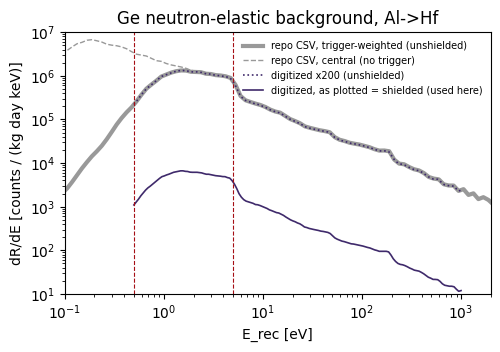

digitized x200 / repo-CSV (trigger-weighted): {0.5: 0.987, 1: 0.994, 2: 0.999, 5: 0.972, 10: 0.983, 100: 0.99, 1000: 0.99}
E_thr=0.5 eV: B shielded 8.361e+01; unshielded: digitized x200 1.672e+04, repo CSV 1.699e+04 counts/(kg day)
E_thr=  5 eV: B shielded 6.039e+01; unshielded: digitized x200 1.208e+04, repo CSV 1.231e+04 counts/(kg day)


In [2]:
ref = pd.read_csv(os.path.join(ROOT, 'artifacts', 'v2.0', 'neutron_dRdErec_ext_AlHf.csv'), comment='#')
Eref = ref.E_rec_keV.values * 1e3
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.loglog(Eref, ref.dRdErec_trigger_weighted, color='0.6', lw=3, label='repo CSV, trigger-weighted (unshielded)')
ax.loglog(Eref, ref.dRdErec_central, color='0.6', lw=1, ls='--', label='repo CSV, central (no trigger)')
ax.loglog(bkg[0.5][:, 0], bkg[0.5][:, 1] * 200, color='#3f2a6b', lw=1.2, ls=':', label='digitized x200 (unshielded)')
ax.loglog(*bkg[0.5].T, color='#3f2a6b', lw=1.2, label='digitized, as plotted = shielded (used here)')
for t in (0.5, 5):
    ax.axvline(t, color='#a50f15', lw=0.8, ls='--')
ax.set(xlim=(0.1, 2e3), ylim=(1e1, 1e7), xlabel='E_rec [eV]', ylabel='dR/dE [counts / (kg day keV)]',
       title='Ge neutron-elastic background, Al->Hf')
ax.legend(fontsize=7, frameon=False)
plt.show()

rr = np.interp(np.log10(bkg[0.5][:, 0]), np.log10(Eref), ref.dRdErec_trigger_weighted)
ratio = 200 * bkg[0.5][:, 1] / rr
print('digitized x200 / repo-CSV (trigger-weighted):',
      {e: round(float(np.interp(np.log10(e), np.log10(bkg[0.5][:, 0]), ratio)), 3) for e in (0.5, 1, 2, 5, 10, 100, 1000)})
for t in (0.5, 5):
    s = (Eref > t) & (Eref < 1000)
    Ei = np.r_[t, Eref[s], 1000.]
    b_ref = np.trapezoid(np.interp(np.log10(Ei), np.log10(Eref), ref.dRdErec_trigger_weighted) / 1e3, Ei)
    print(f'E_thr={t:>3} eV: B shielded {B[t]:.3e}; unshielded: digitized x200 {200*B[t]:.3e}, repo CSV {b_ref:.3e} counts/(kg day)')

The solid curve's roll-off below about 2 eV is the **trigger efficiency**; compare the central column (dashed grey), which has no trigger. So the background is trigger-weighted, while the DM signal below is *not* smeared or trigger-weighted. Only the flat 50% efficiency is applied to the signal.

## 2. Signal: DarkELF Ge, and the free-nucleus kinematic edge

For a free Ge nucleus, the maximum recoil is $E_{R,\max} = 2\mu^2 v_{\max}^2/m_N$, with $v_{\max} = v_{\rm esc} + v_E = 784$ km/s. Below the mass where $E_{R,\max} = E_{\rm thr}$, DarkELF still gives a rate. That rate comes only from the Gaussian tail of the impulse approximation, which is model-dependent.

free-nucleus edge: E_R,max = 0.5 eV at m = 50 MeV
free-nucleus edge: E_R,max = 5 eV at m = 157 MeV


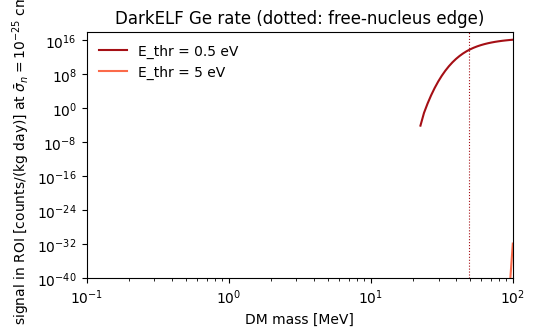

E_thr=0.5 eV: signal > 0 from 22.4 MeV; at 100 MeV 1.305e+16 counts/(kg day)
E_thr=  5 eV: signal > 0 from 53.1 MeV; at 100 MeV 1.356e-32 counts/(kg day)


In [3]:
mN, vmax = 72 * 0.9315e9, (544 + 240) / 2.998e5
edge = {}
for t in (0.5, 5):
    mu = np.sqrt(t * mN / (2 * vmax**2))
    edge[t] = mu * mN / (mN - mu) / 1e6
    print(f'free-nucleus edge: E_R,max = {t} eV at m = {edge[t]:.0f} MeV')

fig, ax = plt.subplots(figsize=(5.5, 3.2))
for t, c in ((0.5, '#a50f15'), (5, '#fb6a4a')):
    m, r = rate[t].T
    ok = r > 0
    ax.loglog(m[ok], r[ok], color=c, label=f'E_thr = {t} eV')
    ax.axvline(edge[t], color=c, lw=0.8, ls=':')
ax.set(xlim=(0.1, 100), ylim=(1e-40, 1e18), xlabel='DM mass [MeV]',
       ylabel=r'signal in ROI [counts/(kg day)] at $\bar\sigma_n=10^{-25}$ cm$^2$',
       title='DarkELF Ge rate (dotted: free-nucleus edge)')
ax.legend(frameon=False)
plt.show()
for t in (0.5, 5):
    m, r = rate[t].T
    print(f'E_thr={t:>3} eV: signal > 0 from {m[r > 0].min():.1f} MeV; at 100 MeV {r[-1]:.3e} counts/(kg day)')

## 3. Limits

$\bar\sigma_n^{90} = 10^{-25}\,{\rm cm^2}\times 1.2816\sqrt{B\,X}\,/\,(0.5\,S_{\rm ref}\,X)$ for exposure $X$ (kg·day), and $\bar\sigma_n^{S=B} = 10^{-25}\,{\rm cm^2}\times B/(0.5\,S_{\rm ref})$, where $S_{\rm ref}$ is the signal rate at $10^{-25}$ cm².

The unshielded rows are the same curves with $B \to 200B$.

In [4]:
m = s05[:, 0]
curves = {
    ('0.5 eV', '90% CL, 1 kg day'): s05[:, 1], ('0.5 eV', '90% CL, 1 kg yr'): s05[:, 2],
    ('0.5 eV', 'S = B'): s05[:, 3], ('5 eV', 'S = B'): s5[:, 1],
}
shield = {'90% CL, 1 kg day': np.sqrt(200), '90% CL, 1 kg yr': np.sqrt(200), 'S = B': 200}

def first_below(s, t):
    return f'{m[s < t].min():.1f}' if (s < t).any() else 'never'

rows = []
for (thr, stat), s in curves.items():
    for bg, f in (('shielded (as plotted)', 1), ('unshielded (x200)', shield[stat])):
        sv = s * f
        rows.append({'E_thr': thr, 'statistic': stat, 'background': bg,
                     'signal > 0 from [MeV]': f'{m[np.isfinite(sv)].min():.1f}',
                     '< 1e-25 from [MeV]': first_below(sv, 1e-25), '< 1e-30 from [MeV]': first_below(sv, 1e-30),
                     **{f'sigma @ {mm} MeV': sv[np.argmin(abs(m - mm))] for mm in (30, 50, 100)}})
tab = pd.DataFrame(rows)
pd.set_option('display.float_format', '{:.2e}'.format)
tab

,E_thr,statistic,background,signal > 0 from [MeV],< 1e-25 from [MeV],< 1e-30 from [MeV],sigma @ 30 MeV,sigma @ 50 MeV,sigma @ 100 MeV
0,0.5 eV,"90% CL, 1 kg day",shielded (as plotted),22.4,26.6,31.6,1.24e-30,3.28e-38,1.80e-40
1,0.5 eV,"90% CL, 1 kg day",unshielded (x200),22.4,26.6,31.6,1.75e-29,4.63e-37,2.54e-39
2,0.5 eV,"90% CL, 1 kg yr",shielded (as plotted),22.4,25.1,29.9,6.47e-32,1.71e-39,9.40e-42
3,0.5 eV,"90% CL, 1 kg yr",unshielded (x200),22.4,26.6,29.9,9.15e-31,2.42e-38,1.33e-40
4,0.5 eV,S = B,shielded (as plotted),22.4,26.6,31.6,8.82e-30,2.34e-37,1.28e-39
5,0.5 eV,S = B,unshielded (x200),22.4,28.2,35.5,1.76e-27,4.67e-35,2.56e-37
6,5 eV,S = B,shielded (as plotted),53.1,never,never,inf,inf,8.91e+08
7,5 eV,S = B,unshielded (x200),53.1,never,never,inf,inf,1.78e+11


QPD baseline (3 meV, 2 Hz): min 3.02e-26 cm^2 at 15.8 MeV; reach 0.1-100 MeV
QPD goal (1 meV, 0.01 Hz): min 1.50e-28 cm^2 at 15.8 MeV; reach 0.1-100 MeV


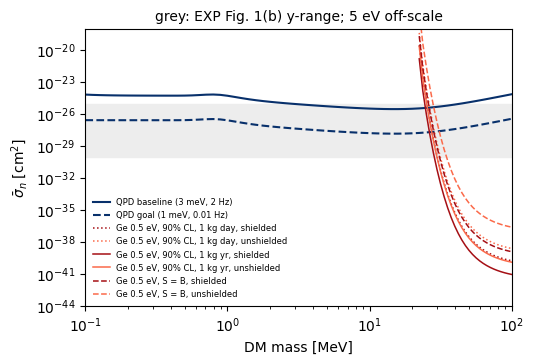

In [5]:
qd = os.path.join(D, 'qpd_reference')
nr, nr3 = (np.loadtxt(os.path.join(qd, f), comments='#', delimiter=',') for f in ('nrhm_rate_per_ng_split.csv', 'nrhm_rate_per_ng_3meV.csv'))
m_target = 110e-4**2 * 7 * np.pi / 8 * 200e-7 * 2.7 * 1e9  # ng, two 7pi/8 Al fins
qpd = {'QPD baseline (3 meV, 2 Hz)': 1e-25 * 2.0 / (0.5 * m_target * (nr3[:, 1] + nr3[:, 2])),
       'QPD goal (1 meV, 0.01 Hz)': 1e-25 * 0.01 / (0.5 * m_target * (nr[:, 1] + nr[:, 2]))}
for k, s in qpd.items():
    i = np.argmin(s)
    print(f'{k}: min {s[i]:.2e} cm^2 at {nr[i, 0]:.1f} MeV; reach 0.1-100 MeV')

fig, ax = plt.subplots(figsize=(5.5, 3.6))
for (k, s), ls in zip(qpd.items(), ('-', '--')):
    ax.loglog(nr[:, 0], s, color='#08306b', ls=ls, label=k)
for (thr, stat), s in curves.items():
    if thr == '5 eV':
        continue
    ls = {'90% CL, 1 kg day': ':', '90% CL, 1 kg yr': '-', 'S = B': '--'}[stat]
    ax.loglog(m, s, color='#a50f15', ls=ls, lw=1.1, label=f'Ge 0.5 eV, {stat}, shielded')
    ax.loglog(m, s * shield[stat], color='#fb6a4a', ls=ls, lw=1.1, label=f'Ge 0.5 eV, {stat}, unshielded')
ax.axhspan(1e-30, 1e-25, color='0.93', zorder=-5)
ax.set(xlim=(0.1, 100), ylim=(1e-44, 1e-18), xlabel='DM mass [MeV]', ylabel=r'$\bar\sigma_n$ [cm$^2$]',
       )
ax.set_title('grey: EXP Fig. 1(b) y-range; 5 eV off-scale', fontsize=10)
ax.legend(fontsize=6, frameon=False, loc='lower left')
plt.show()

### Pipeline figures (panel-(b) style, shielded background as plotted)

* `figs/ge_substrate/ge_substrate_limit.png`: 0.5 eV, 1 kg·day (dotted) and 1 kg·yr (solid), y = 1e-30 to 1e-25.
* `figs/ge_substrate/ge_substrate_limit_wide.png`: the same down to 1e-42, plus S = B.
* `figs/ge_substrate/ge_substrate_limit_5eV.png`: 5 eV, **S = B only**, with the 0.5 eV S = B curve dotted for comparison.

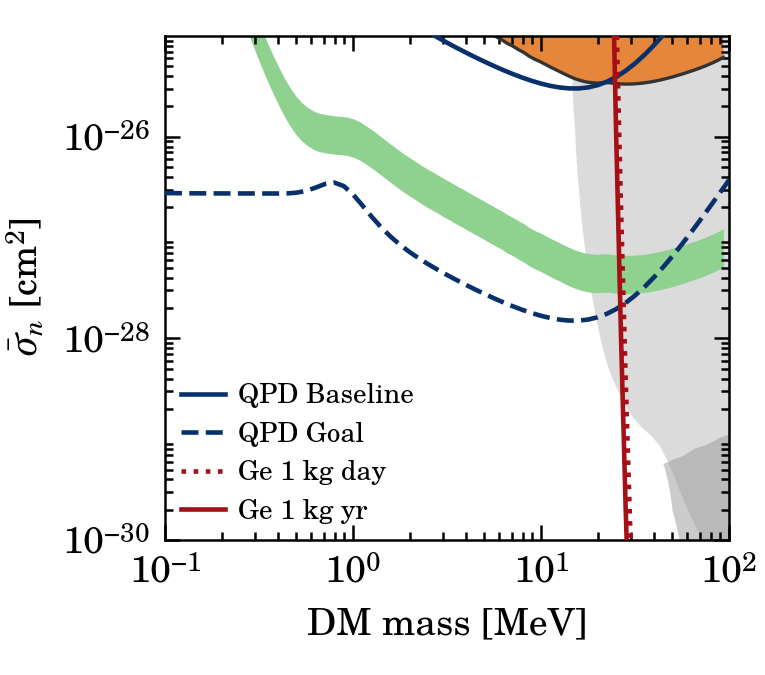

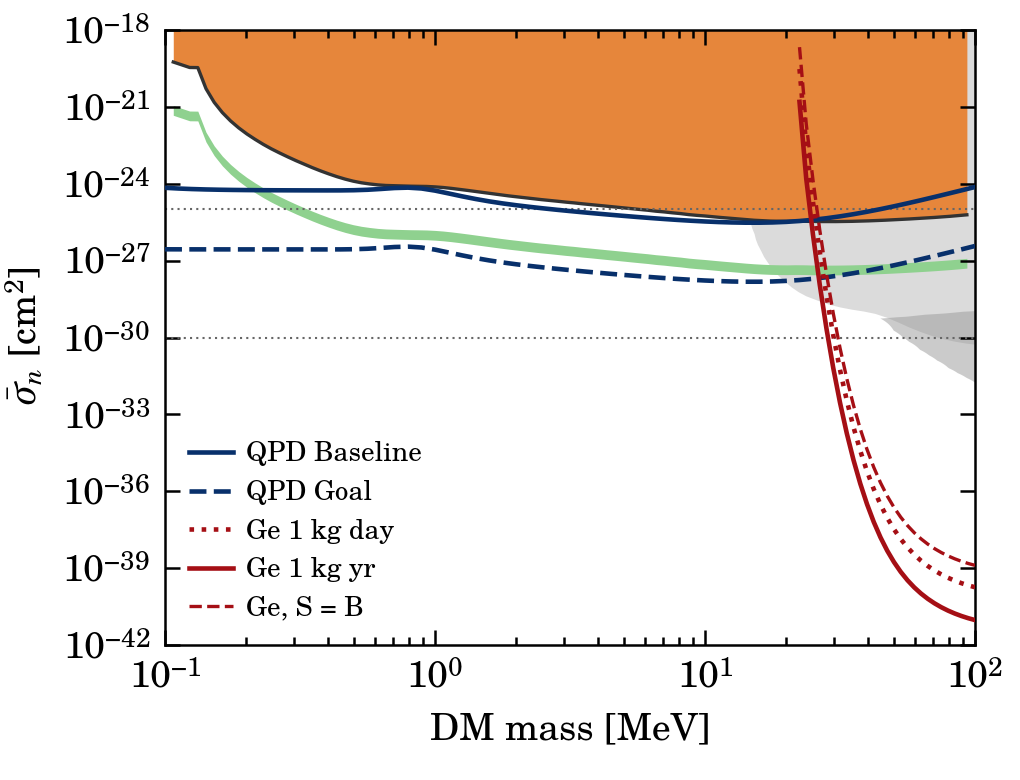

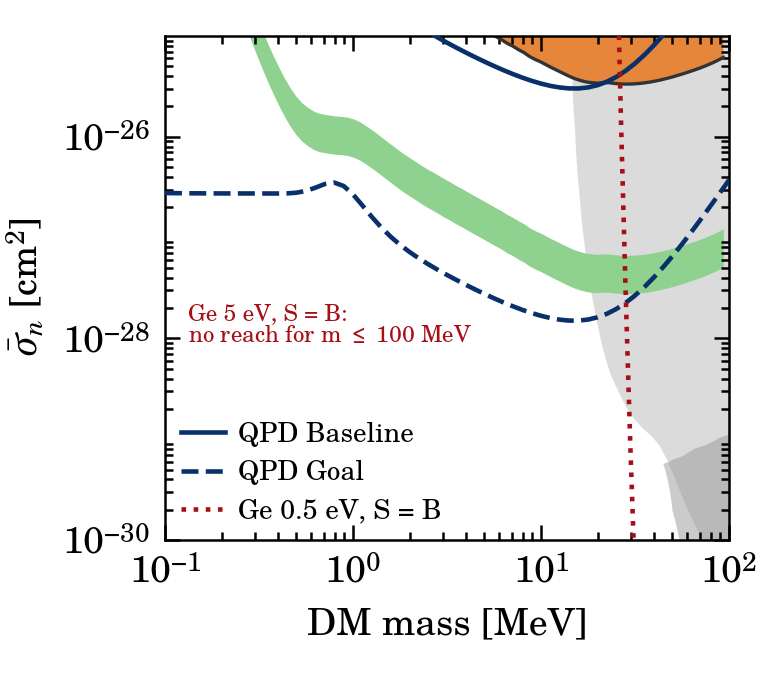

In [6]:
for f in ('ge_substrate_limit.png', 'ge_substrate_limit_wide.png', 'ge_substrate_limit_5eV.png'):
    display(Image(os.path.join(F, f), width=420))

## 4. Findings

* **No reach where QPD is strongest.** A 0.5 eV Ge search has **zero signal below 22 MeV**. QPD baseline and goal reach down to 0.1 MeV, with minima of 3.0e-26 and 1.5e-28 cm² at 16 MeV.
* **Reach above about 30 MeV.** The kg-scale exposure (about 1e11 × the QPD target mass) goes 10 or more orders of magnitude below QPD there. In the Fig. 1(b) window (1e-30 to 1e-25) the Ge curve is a **near-vertical wall at 25–32 MeV**, whatever the statistic. The unshielded case moves it by at most about 4 MeV.
* **0.5 eV, shielded (default, as plotted):** B = 84 counts/(kg day). σ̄_n reaches 1.2e-30 / 3.3e-38 / 1.8e-40 cm² (1 kg·day) and 6.5e-32 / 1.7e-39 / 9.4e-42 (1 kg·yr) at 30 / 50 / 100 MeV. S = B gives 8.8e-30 / 2.3e-37 / 1.3e-39. The curve drops below 1e-25 at 25–27 MeV and below 1e-30 at 30–32 MeV.
* **0.5 eV, unshielded (×200, reference):** B = 1.67e4 counts/(kg day). S = B is 200× worse (1.8e-27 / 4.7e-35 / 2.6e-37), and counting is about 14× worse (1 kg·yr: 9.2e-31 / 2.4e-38 / 1.3e-40). The turn-on mass hardly moves, because it is set by kinematics, not by the background.
* **5 eV (S = B):** B = 60 counts/(kg day) shielded (1.21e4 unshielded). There is **no reach anywhere in 0.1–100 MeV**: the signal is zero below 53 MeV, and σ̄_n ≈ 9e8 cm² at 100 MeV (2e11 unshielded). The free-nucleus edge is at 157 MeV.
* **Bottom line.** For sub-GeV heavy-mediator DM, a Ge substrate is a >30 MeV instrument. The 0.1–20 MeV band in EXP Fig. 1(b) is reachable only with meV-scale thresholds like the QPD's; a heavier, lower-background target cannot make up for a higher threshold.

## 5. Caveats and guessed numbers

* **Digitization.** The axis calibration comes from tick pixels. The result is checked against the repo CSV: 1–3% in the ROI.
* **Neutron rate accuracy.** The repo labels the neutron rate `order_of_magnitude`. Only the >10 MeV flux integral is anchored (Gordon 2004); the eV–keV shape is not validated. The factor-200 shield is an *assumed* performance.
* **Signal response.** The signal is not trigger-weighted or resolution-smeared, while the background is. The 50% efficiency is assumed, not derived.
* **Model tail.** At 0.5 eV, the reach between 22 and about 50 MeV rests on the DarkELF impulse-approximation tail (free-nucleus edge ≈ 50 MeV). Treat it as optimistic. At 5 eV the edge is about 157 MeV, so the whole panel range lies on that tail, and the tail is negligible.
* **One background.** Neutron elastic only, as asked. No Compton, muon, cosmogenic lines, reactor-correlated neutrons, or an unknown low-energy excess. In real sub-eV detectors, the low-energy excess would likely dominate.
* **Statistics.** There is no background systematic. A 1% systematic floors $N_{90}$ at about $0.013B$, which exceeds $1.28\sqrt{B}$ once $B \gtrsim 10^4$. With the shielded B this matters only near 1 kg·yr ($B \approx 3\times10^4$), where the curve would be about 2× optimistic. Unshielded, it already applies at 1 kg·day.

## 6. Reproduce

```bash
/opt/anaconda3/envs/straxion/bin/python scripts/ge_substrate_limit.py      # 0.5 eV (writes data/ + figs/ge_substrate)
/opt/anaconda3/envs/straxion/bin/python scripts/ge_substrate_limit.py 5    # 5 eV, S = B only (needs the 0.5 eV run)
```

You need DarkELF at `/Users/lanqingyuan/Documents/GitHub/DarkELF` and the TeX Gyre Schola fonts from TeX Live 2026. DarkELF rates are cached in `data/ge_substrate/ge_rate_per_kg_day*.csv`; delete them to recompute (about 15 s each). `data/ge_substrate/qpd_reference/` holds the QPD and existing-limit curves of EXP Fig. 1(b), copied from QMIT/support/figure on 2026-11-07.